<a href="https://colab.research.google.com/github/sgulyano/CMKL41-685/blob/main/41_685lab_TripoSR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CMKL41-685 Lab: Single-Image 3D Reconstruction with TripoSR

CMKL University

By Sarun Gulyanon

### Goal

Introduce students how a feed-forward model can turn one image into a 3D mesh in the **single image to 3D reconstruction** task.

### Outline

In this lab, students will use [TripoSR method](https://arxiv.org/abs/2403.02151)
Introduce students to **single image to 3D reconstruction** task.

### References
1. Tochilkin et al. (2024). *TripoSR: Fast 3D Object Reconstruction from a Single Image.* [arXiv:2403.02151](https://arxiv.org/abs/2403.02151).
2. Hong et al. (2023). *LRM: Large Reconstruction Model for Single Image to 3D.* arXiv:2311.04400.
3. TripoSR model and code: https://huggingface.co/stabilityai/TripoSR, https://github.com/VAST-AI-Research/TripoSR
4. Wang et al. (2018). *Pixel2Mesh.* https://github.com/nywang16/Pixel2Mesh

## 0. Setup and Imports

In [ ]:
import torch
print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


Install dependencies (about 1-2 min)

In [ ]:
%%bash
set -e
# Clone the official TripoSR code
if [ ! -d TripoSR ]; then
  git clone --depth 1 https://github.com/VAST-AI-Research/TripoSR.git
fi

# Install everything EXCEPT torchmcubes (it is the part that breaks).
# transformers is kept below v5 because TripoSR was written against the 4.x API.
pip install -q omegaconf einops "transformers>=4.40,<5" trimesh \
    huggingface_hub "imageio[ffmpeg]" xatlas moderngl scikit-image \
    rembg onnxruntime
echo "Dependencies installed."

Dependencies installed.


Cloning into 'TripoSR'...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


Replace `torchmcubes` with a scikit-image version. TripoSR does `from torchmcubes import marching_cubes`. But torchmcubes frequently break or failed so we replace it with a file we created inside the repo folder.

In [ ]:
import os, sys

os.chdir("/content/TripoSR")
sys.path.insert(0, os.getcwd())

shim = """
import numpy as np
import torch
from skimage import measure


def marching_cubes(vol, thresh):
    \"\"\"Drop-in replacement for torchmcubes.marching_cubes using scikit-image.\"\"\"
    v = vol.detach().float().cpu().numpy()
    verts, faces, _, _ = measure.marching_cubes(v, level=float(thresh))
    # torchmcubes returns vertices in reversed axis order; TripoSR flips them back.
    verts = np.ascontiguousarray(verts[:, [2, 1, 0]])
    return (
        torch.from_numpy(verts).float(),
        torch.from_numpy(faces.astype(np.int64)),
    )
"""
with open("torchmcubes.py", "w") as f:
    f.write(shim)
print("Wrote torchmcubes.py shim in", os.getcwd())

Wrote torchmcubes.py shim in /content/TripoSR


In [ ]:
import numpy as np
from PIL import Image
import rembg
import time
import trimesh

from tsr.system import TSR
from tsr.utils import remove_background, resize_foreground

device = "cuda:0" if torch.cuda.is_available() else "cpu"

## 1. Load the model from Hugging Face and Prepare Input Image

In [ ]:
model = TSR.from_pretrained(
    "stabilityai/TripoSR",
    config_name="config.yaml",
    weight_name="model.ckpt",
)
model.renderer.set_chunk_size(8192)  # lower (e.g. 4096) if you hit out-of-memory
model.to(device)
print("Model loaded on", device)

config.yaml:   0%|          | 0.00/987 [00:00<?, ?B/s]

model.ckpt:   0%|          | 0.00/1.68G [00:00<?, ?B/s]

config.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

Model loaded on cuda:0


Get the input image. Use a single object, clear view, plain or simple background.

Input: /content/TripoSR/examples/chair.png (512, 512)


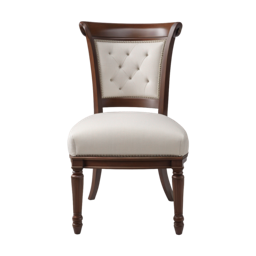

In [ ]:
image_path = "/content/TripoSR/examples/chair.png"
input_image = Image.open(image_path)
print("Input:", image_path, input_image.size)
input_image.convert("RGBA").resize((256, 256))

And remove its background.

  0%|                                              | 0.00/1.02G [00:00<?, ?B/s]

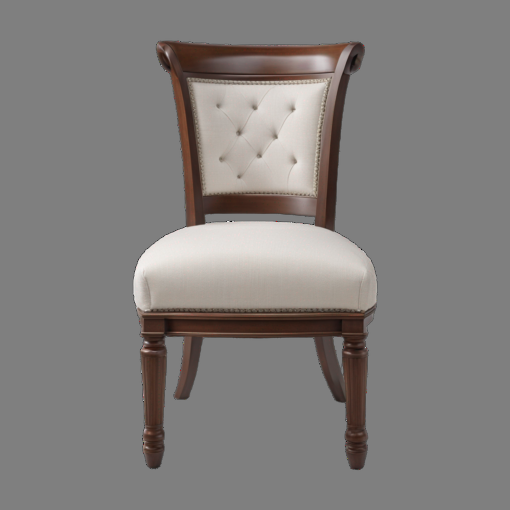

In [ ]:
FOREGROUND_RATIO = 0.85   # how much of the frame the object fills

rembg_session = rembg.new_session()
image = remove_background(input_image.convert("RGB"), rembg_session)
image = resize_foreground(image, FOREGROUND_RATIO)

# Composite onto neutral gray, which is what the model expects
arr = np.array(image).astype(np.float32) / 255.0
arr = arr[:, :, :3] * arr[:, :, 3:4] + (1 - arr[:, :, 3:4]) * 0.5
processed = Image.fromarray((arr * 255.0).astype(np.uint8))
processed

## 2. Generate the 3D mesh

TripoSR leverages the transformer architecture and is specifically designed for single-image 3D reconstruction. It takes a single RGB image as input and outputs a 3D representation of the object in the image.

![TripoSR](https://raw.githubusercontent.com/sgulyano/sgulyano.github.io/51974cf447139bb32a72a28cdb746e3c92e95b2b/img/lab/triposr.png)

The core of TripoSR includes components: an image encoder,
an image-to-triplane decoder, and a triplane-based neural
radiance field (NeRF).

The image encoder is initialized with a pre-trained vision
transformer model, DINOv1, which projects an RGB
image into a set of latent vectors. The subsequent image-to-triplane decoder transforms the latent vectors onto the triplane-NeRF representation.

Finally, the NeRF model consists of a stack of multilayer perceptrons (MLPs), which are responsible for predicting the
color and density of a 3D point in space.

![NeRF](https://raw.githubusercontent.com/sgulyano/sgulyano.github.io/51974cf447139bb32a72a28cdb746e3c92e95b2b/img/lab/nerf.png)

We then extract the isosurface using Marching Cubes to convert implicit 3D representations (such as NeRF) into meshes.


In [ ]:
MC_RESOLUTION = 256   # marching-cubes grid; 256 is the default, 320 gives finer detail

t0 = time.time()
with torch.no_grad():
    scene_codes = model([processed], device=device)
print("Triplane shape:", tuple(scene_codes.shape), "(batch, 3 planes, channels, H, W)")

kwargs = dict(resolution=MC_RESOLUTION, has_vertex_color=True)
mesh = model.extract_mesh(scene_codes, **kwargs)[0]

# Make triangle winding / normals consistent (the shim can flip orientation)
trimesh.repair.fix_normals(mesh)

print(f"Done in {time.time()-t0:.1f}s | vertices: {len(mesh.vertices):,} | faces: {len(mesh.faces):,}")

Triplane shape: (1, 3, 40, 64, 64) (batch, 3 planes, channels, H, W)
Done in 6.4s | vertices: 41,429 | faces: 82,870


Use Plotly to give 3D preview.

In [ ]:
import plotly.graph_objects as go

v, f = np.asarray(mesh.vertices), np.asarray(mesh.faces)
colors = None
if getattr(mesh.visual, "vertex_colors", None) is not None and len(mesh.visual.vertex_colors) == len(v):
    c = np.asarray(mesh.visual.vertex_colors)[:, :3]
    colors = [f"rgb({r},{g},{b})" for r, g, b in c]

fig = go.Figure(go.Mesh3d(
    x=v[:, 0], y=v[:, 1], z=v[:, 2],
    i=f[:, 0], j=f[:, 1], k=f[:, 2],
    vertexcolor=colors, flatshading=True,
))
fig.update_layout(scene=dict(aspectmode="data"), height=600, margin=dict(l=0, r=0, t=0, b=0))
fig.show()

---